# Biblio 

In [13]:
import pandas as pd
import numpy as np

# 1 Observer et comparer

=== Mouse ===
Shape X : (500, 2)
Valeurs manquantes :
 x1    0
x2    0
dtype: int64
Nb anomalies : 10 (2.00 %)
         x1        x2
0  0.456601  0.432806
1  0.611378  0.528625
2  0.450299  0.711606
3  0.639015  0.460744
4  0.628957  0.323470


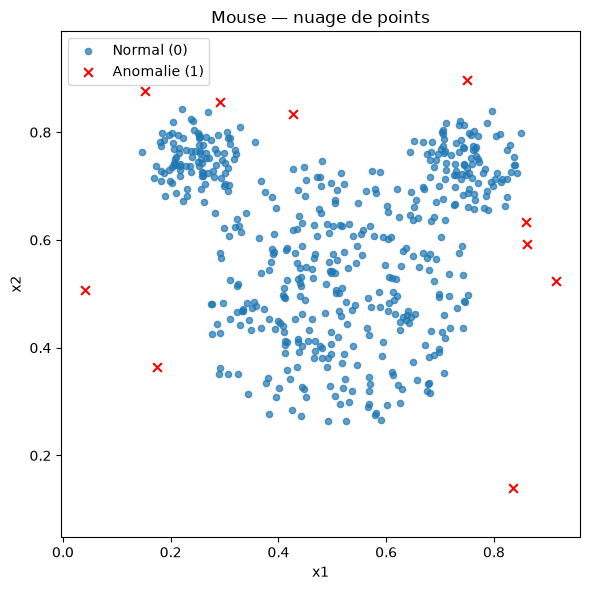

In [14]:
from utils_mouse import load_mouse, check_dataset, plot_mouse

X_mouse, y_mouse = load_mouse("../data/mouse.txt")
check_dataset(X_mouse, y_mouse, name="Mouse")
plot_mouse(X_mouse, y_mouse)

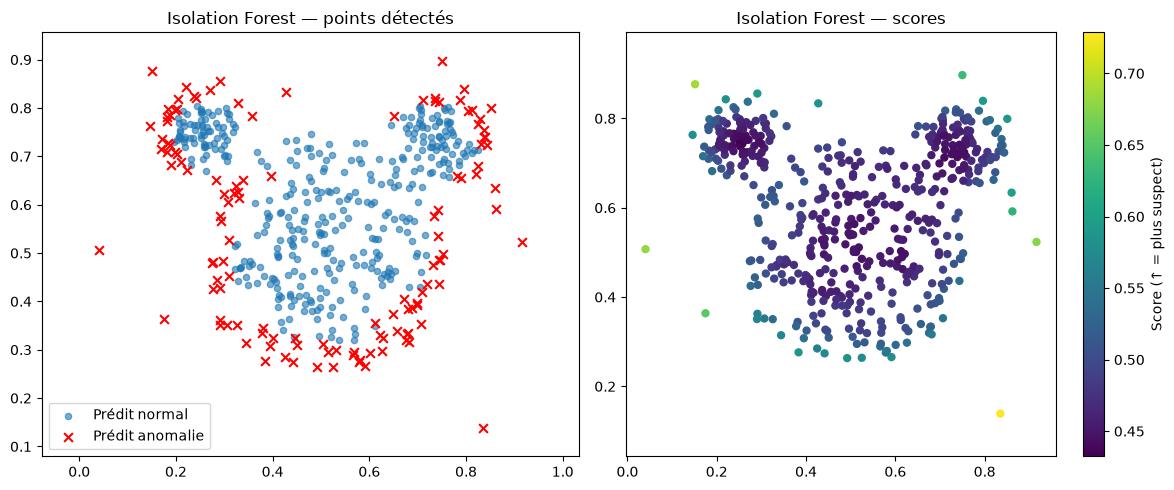

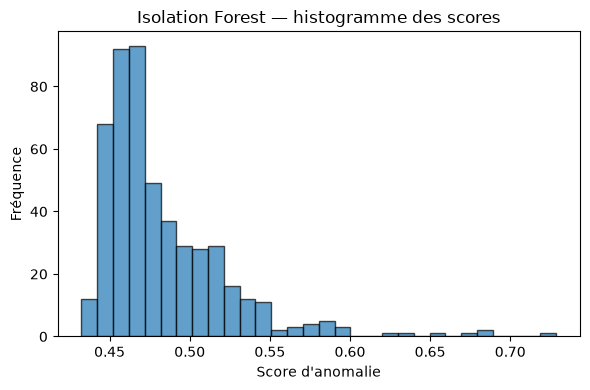

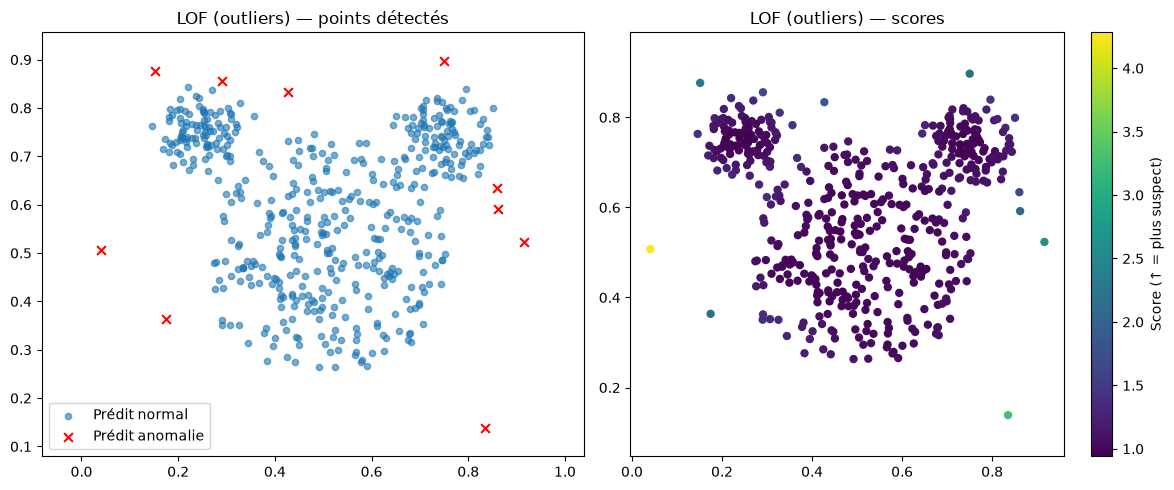

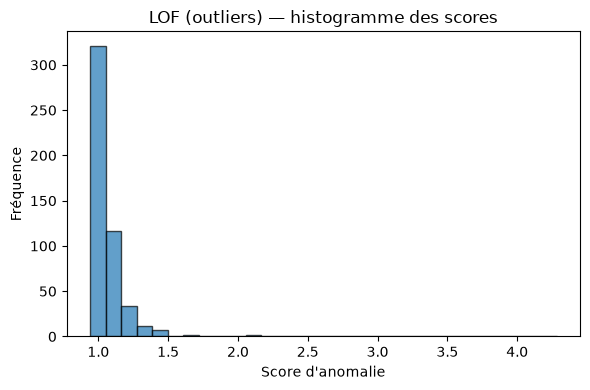

In [15]:
import importlib
import utils_mouse
importlib.reload(utils_mouse)

from utils_mouse import fit_isolation_forest, fit_lof_outliers, plot_detection, compare_thresholds

# Isolation Forest
if_model, if_scores, if_pred = fit_isolation_forest(X_mouse)
plot_detection(X_mouse, if_pred, if_scores, "Isolation Forest")

# LOF (mode outliers)
lof_model, lof_scores, lof_pred = fit_lof_outliers(X_mouse)
plot_detection(X_mouse, lof_pred, lof_scores, "LOF (outliers)")

In [16]:
print("IF anomalies prédites :", if_pred.sum())
print("LOF anomalies prédites :", lof_pred.sum())
print("Vraies anomalies (labels) :", y_mouse.sum())  # toujours 10

IF anomalies prédites : 125
LOF anomalies prédites : 10
Vraies anomalies (labels) : 10


Sur Mouse, IF et LOF donnent des comportements différents :

IF : beaucoup d’alertes (bords des groupes) → rappel potentiellement élevé, mais précision faible avec le seuil par défaut
LOF : peu d’alertes → plus proche du nombre réel d’anomalies, à confirmer quantitativement

## 2. Choix d’un seuil sans étiquettes
### Principe
Les modèles fournissent un **score continu**. Le **seuil** transforme ce score en décision (normal / anomalie).
Nous comparons deux règles :
1. **Seuil par défaut** de scikit-learn (`contamination` / règle interne)
2. **Seuil IQR** : `seuil = Q3 + 1.5 × IQR` sur les scores
Le coefficient `k=1.5` est une **convention statistique** (Tukey), fixé **a priori**.
Il n’a **pas** été choisi en consultant les labels (pas de fuite d’information).
Les labels servent uniquement à l’**évaluation** (matrice de confusion, F1).


######## Isolation Forest — seuil PAR DÉFAUT ########

=== Isolation Forest | défaut ===
Seuil → nb alertes : 125
Matrice de confusion [[TN FP],[FN TP]] :
 [[375 115]
 [  0  10]]
F1 (classe anomalie) : 0.1481


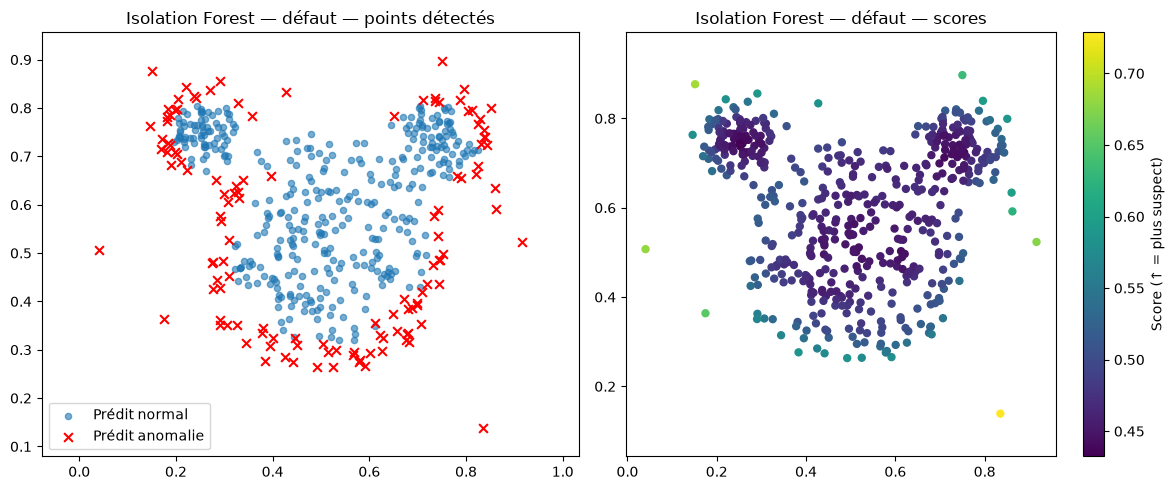

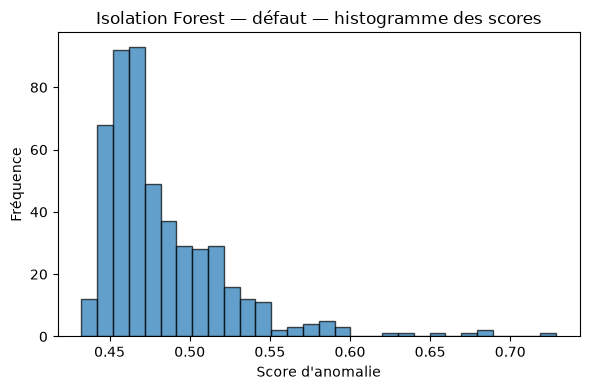


######## Isolation Forest — seuil IQR ########
Seuil IQR = 0.562563

=== Isolation Forest | IQR ===
Seuil → nb alertes : 21
Matrice de confusion [[TN FP],[FN TP]] :
 [[479  11]
 [  0  10]]
F1 (classe anomalie) : 0.6452


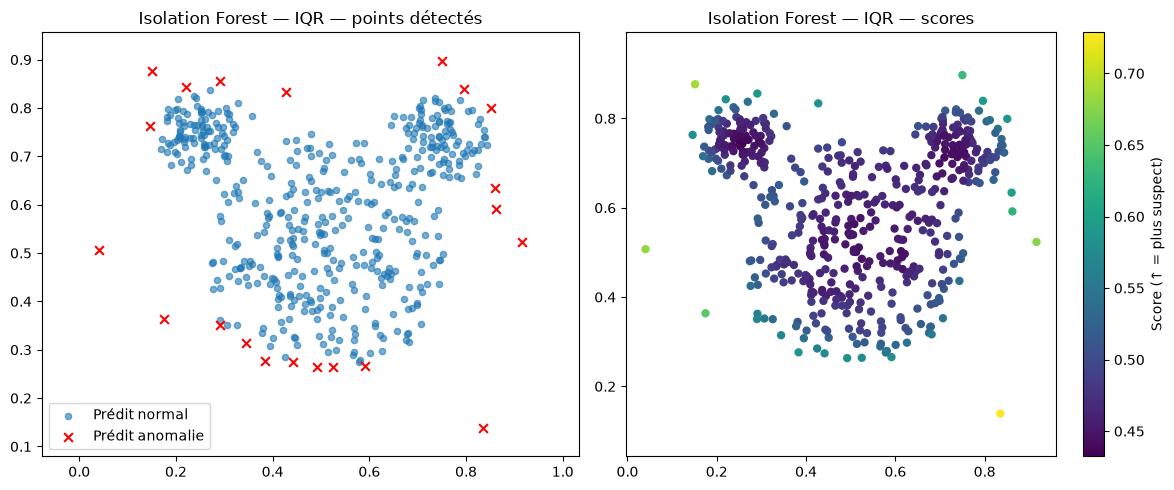

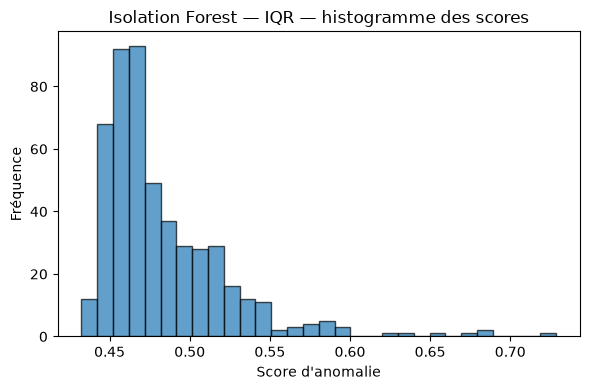


######## LOF — seuil PAR DÉFAUT ########

=== LOF | défaut ===
Seuil → nb alertes : 10
Matrice de confusion [[TN FP],[FN TP]] :
 [[490   0]
 [  0  10]]
F1 (classe anomalie) : 1.0


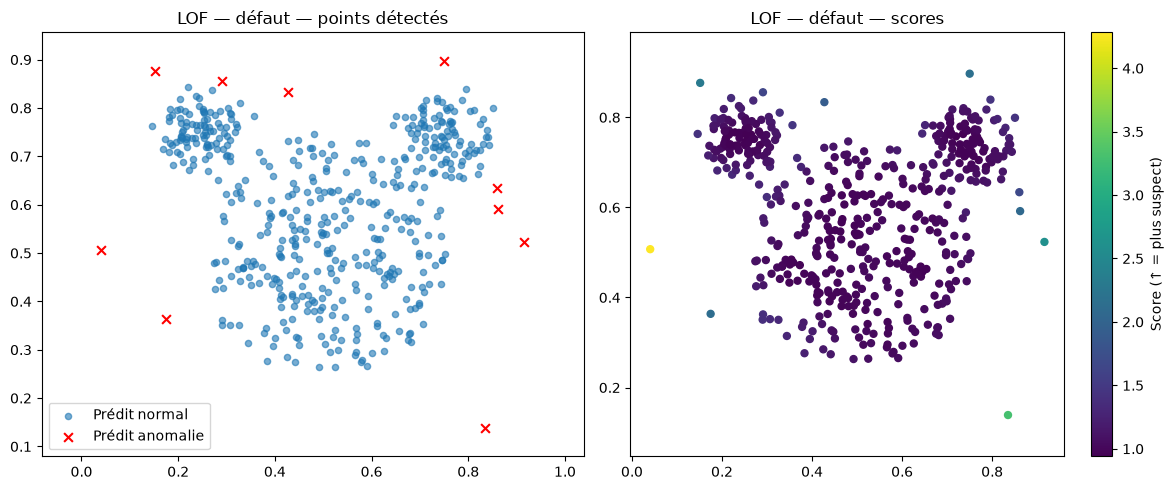

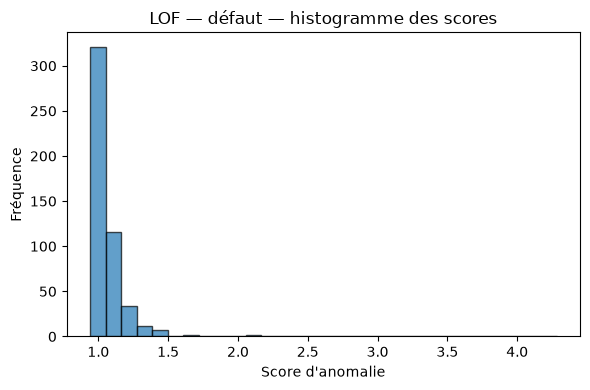


######## LOF — seuil IQR ########
Seuil IQR = 1.225625

=== LOF | IQR ===
Seuil → nb alertes : 37
Matrice de confusion [[TN FP],[FN TP]] :
 [[463  27]
 [  0  10]]
F1 (classe anomalie) : 0.4255


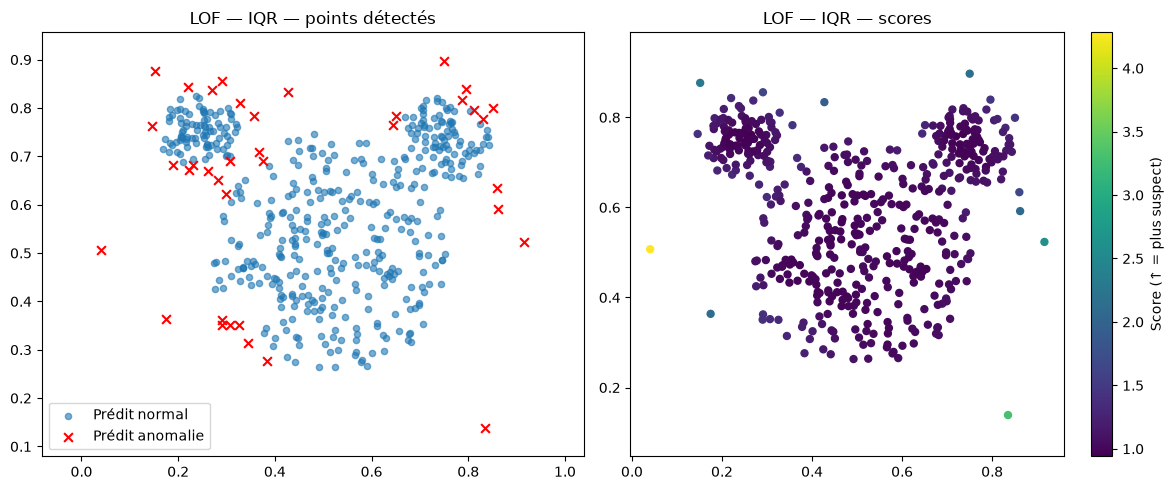

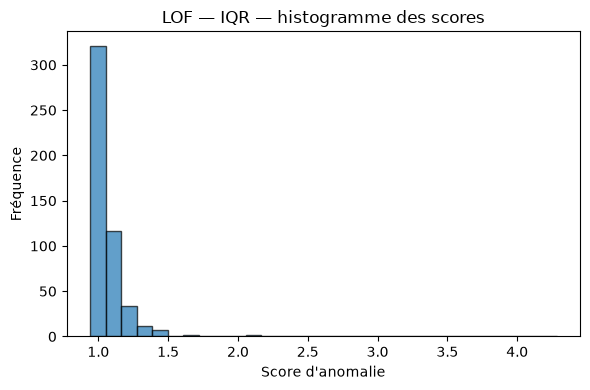

In [17]:
import importlib
import utils_mouse
importlib.reload(utils_mouse)

from utils_mouse import compare_thresholds

# IF : défaut vs IQR
thr_if_iqr, if_pred_iqr = compare_thresholds(
    X_mouse, y_mouse, if_scores, if_pred, method_name="Isolation Forest"
)

# LOF : défaut vs IQR
thr_lof_iqr, lof_pred_iqr = compare_thresholds(
    X_mouse, y_mouse, lof_scores, lof_pred, method_name="LOF"
)

### Tableau comparatif
| Méthode | Règle de seuil | Nb alertes | F1 anomalie | Commentaire |
|---------|----------------|------------|-------------|-------------|
| IF | Défaut | 125 | 0.148 | |
| IF | IQR (k=1.5) | 21 | 0.645 | |
| LOF | Défaut | 10 | 1.000 | |
| LOF | IQR (k=1.5) | 37| 0.426 | |


*(référence : 10 vraies anomalies)*

À quoi sert le F1 (classe anomalie) ?
C’est une note unique pour juger si tes détections sont bonnes, en mélangeant 2 choses :

Précision : parmi les alertes, combien sont de vraies anomalies ?
Rappel : parmi les vraies anomalies, combien as-tu trouvées 
F1 = moyenne "équilibrée" de précision et rappel

Rappel : AP et AUC utilisent les SCORES, pas y_pred. Changer le seuil ne les change pas.

=== Isolation Forest — classement ===
Average Precision (AP) : 0.9614
AUC-ROC               : 0.999


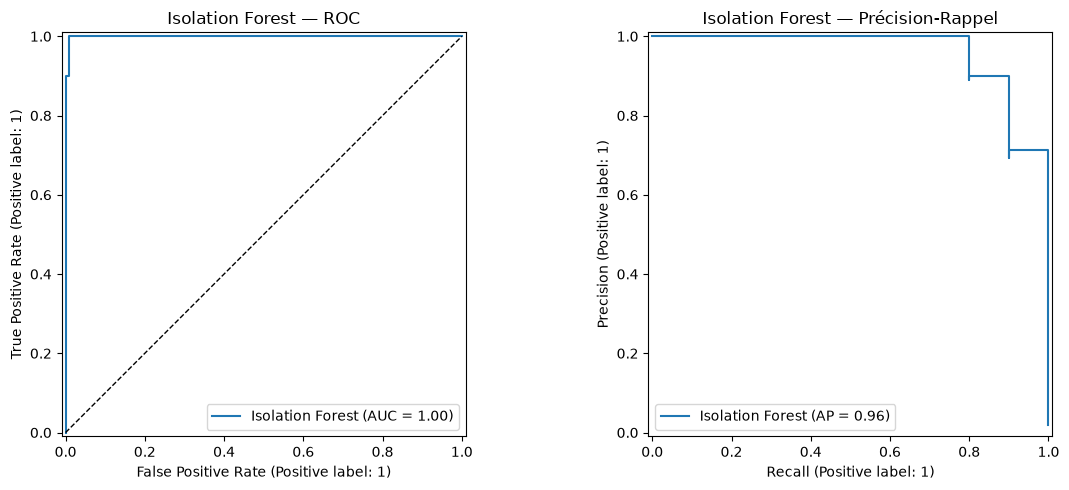


=== LOF — classement ===
Average Precision (AP) : 1.0
AUC-ROC               : 1.0


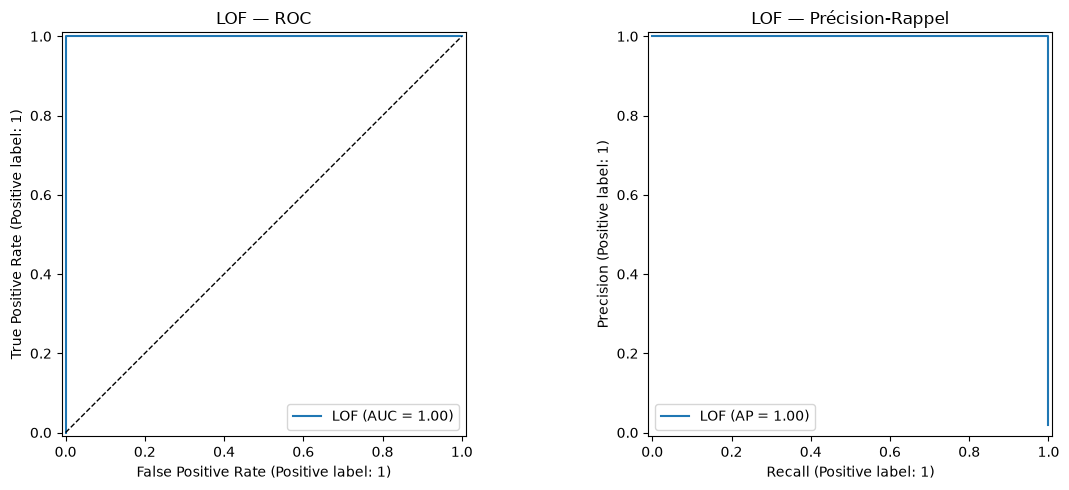


Preuve : AP IF avec scores = 0.9614
Si on changeait seulement le seuil, AP resterait = 0.9614


In [18]:
import importlib
import utils_mouse
importlib.reload(utils_mouse)

from utils_mouse import ranking_metrics, plot_ranking_curves

# Les scores sont les mêmes avant/après IQR → AP/AUC identiques quel que soit le seuil
print("Rappel : AP et AUC utilisent les SCORES, pas y_pred. Changer le seuil ne les change pas.")

m_if = ranking_metrics(y_mouse, if_scores, name="Isolation Forest")
plot_ranking_curves(y_mouse, if_scores, name="Isolation Forest")

m_lof = ranking_metrics(y_mouse, lof_scores, name="LOF")
plot_ranking_curves(y_mouse, lof_scores, name="LOF")

# Preuve rapide : même scores → mêmes métriques, même si on change y_pred
print("\nPreuve : AP IF avec scores =", round(m_if["AP"], 4))
print("Si on changeait seulement le seuil, AP resterait =", round(m_if["AP"], 4))